In [2]:
from google.colab import files
uploaded = files.upload()

Saving amazon.csv to amazon (1).csv


In [4]:
import pandas as pd
import numpy as np
import re
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras import layers, Model

df = pd.read_csv(list(uploaded.keys())[0])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.columns.tolist())
df.head()

Dataset loaded successfully!
Dataset shape: (1465, 16)
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [5]:
# Remove duplicate product IDs
if "product_id" in df.columns:
    df = df.drop_duplicates(subset=["product_id"]).copy()
else:
    df = df.drop_duplicates().copy()

# Clean numerical columns
numeric_cols = [
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating",
    "rating_count"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype(str)
            .str.replace(",", "", regex=False)
            .str.replace("₹", "", regex=False)
            .str.replace("%", "", regex=False)
            .str.replace(r"[^0-9.\-]", "", regex=True),
            errors="coerce"
        )

# Remove rows without valid ratings
df = df[df["rating"].between(1, 5)].copy()

# Handle missing text
text_cols = [
    "product_name", "category", "about_product",
    "review_title", "review_content"
]

for col in text_cols:
    df[col] = df[col].fillna("").astype(str)

# Handle missing numerical values
for col in [
    "discounted_price", "actual_price",
    "discount_percentage", "rating_count"
]:
    df[col] = df[col].fillna(df[col].median())

df["discount_percentage"] = df["discount_percentage"].clip(0, 100)

df = df.reset_index(drop=True)

print("Missing values handled!")
print("Remaining records:", len(df))
print(df.isnull().sum())

Missing values handled!
Remaining records: 1350
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64


In [6]:
df["main_category"] = (
    df["category"].str.split("|").str[0]
    .replace("", "Unknown").fillna("Unknown")
)

df["review_text"] = (
    df["product_name"] + " " +
    df["about_product"] + " " +
    df["review_title"] + " " +
    df["review_content"]
).str.lower()

df["review_text"] = df["review_text"].apply(
    lambda x: re.sub(r"\s+", " ", x).strip()
)

display(df[["main_category", "review_text", "rating"]].head())

,main_category,review_text,rating
0,Computers&Accessories,wayona nylon braided usb to lightning fast cha...,4.2
1,Computers&Accessories,ambrane unbreakable 60w / 3a fast charging 1.5...,4.0
2,Computers&Accessories,sounce fast phone charging cable & data sync u...,3.9
3,Computers&Accessories,boat deuce usb 300 2 in 1 type-c & micro usb s...,4.2
4,Computers&Accessories,portronics konnect l 1.2m fast charging 3a 8 p...,4.2


In [7]:
numeric_cols = [
    "discounted_price", "actual_price",
    "discount_percentage", "rating_count"
]

train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42
)

X_train_text = df.loc[train_idx, "review_text"].to_numpy()
X_test_text = df.loc[test_idx, "review_text"].to_numpy()

X_train_cat = df.loc[train_idx, "main_category"].to_numpy()
X_test_cat = df.loc[test_idx, "main_category"].to_numpy()

X_train_num = df.loc[train_idx, numeric_cols].to_numpy(dtype="float32")
X_test_num = df.loc[test_idx, numeric_cols].to_numpy(dtype="float32")

y_train = df.loc[train_idx, "rating"].to_numpy(dtype="float32")
y_test = df.loc[test_idx, "rating"].to_numpy(dtype="float32")

scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_num).astype("float32")
X_test_num = scaler.transform(X_test_num).astype("float32")

print("Training records:", len(y_train))
print("Testing records:", len(y_test))

Training records: 1080
Testing records: 270


In [8]:
MAX_TOKENS = 10000
MAX_LENGTH = 150

text_vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

text_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(X_train_text).batch(32)
)

category_encoder = layers.StringLookup(
    output_mode="one_hot",
    num_oov_indices=1
)

category_encoder.adapt(
    tf.data.Dataset.from_tensor_slices(X_train_cat).batch(32)
)

print("Original review:", X_train_text[0][:150])
print("Encoded sequence:")
print(text_vectorizer(tf.constant([X_train_text[0]])).numpy()[0][:30])

Original review: kingston datatraveler exodia dtx/32 gb pen drive usb 3.2 gen 1 (multicolor) large loop easily attaches to key rings|practical cap protects the usb plu
Encoded sequence:
[6281    1    1    1  667  421  509   39  670  825   52 2706  571 2960
  191    1    4  864    1 1562  895    2   39    1  432  726   60    1
   60    8]


In [9]:
text_input = layers.Input(shape=(), dtype=tf.string, name="review_text")

tokens = text_vectorizer(text_input)

embedding = layers.Embedding(
    MAX_TOKENS, 64, mask_zero=True
)(tokens)

text_features = layers.Bidirectional(
    layers.LSTM(32)
)(embedding)

text_features = layers.Dropout(0.3)(text_features)

numeric_input = layers.Input(
    shape=(len(numeric_cols),), name="numeric_features"
)

numeric_features = layers.Dense(16, activation="relu")(numeric_input)

category_input = layers.Input(
    shape=(), dtype=tf.string, name="category"
)

category_features = category_encoder(category_input)

combined = layers.Concatenate()([
    text_features, numeric_features, category_features
])

combined = layers.Dense(32, activation="relu")(combined)
combined = layers.Dropout(0.2)(combined)

output = layers.Dense(1, activation="linear")(combined)

model = Model(
    inputs=[text_input, numeric_input, category_input],
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review_text         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 150)       │          0 │ review_text[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 64)   │    640,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     24,832 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric_features    │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │         80 │ numeric_features… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_1     │ (None, 10)        │          0 │ category[0][0]    │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 90)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dense[0][0],      │
│                     │                   │            │ string_lookup_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,912 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 667,857 (2.55 MB)

 Trainable params: 667,857 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
train_inputs = {
    "review_text": X_train_text,
    "numeric_features": X_train_num,
    "category": X_train_cat
}

test_inputs = {
    "review_text": X_test_text,
    "numeric_features": X_test_num,
    "category": X_test_cat
}

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_inputs,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 144ms/step - loss: 0.3658 - mae: 0.4846 - val_loss: 0.1696 - val_mae: 0.3161
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 144ms/step - loss: 0.3505 - mae: 0.4653 - val_loss: 0.1750 - val_mae: 0.3295
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 191ms/step - loss: 0.3653 - mae: 0.4757 - val_loss: 0.1719 - val_mae: 0.3220
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 145ms/step - loss: 0.3440 - mae: 0.4696 - val_loss: 0.1489 - val_mae: 0.2850
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 169ms/step - loss: 0.3336 - mae: 0.4577 - val_loss: 0.1443 - val_mae: 0.2829
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 230ms/step - loss: 0.3090 - mae: 0.4379 - val_loss: 0.1731 - val_mae: 0.3242
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 179ms/step - loss: 0.3186 - mae: 0.4469 - val_loss: 0.1396 - val_mae: 0.2656
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 145ms/step - loss: 0.3246 - mae: 0.4491 - val_loss: 0.1389 - val_mae: 0.2536
Epoch 9/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 269ms/step - lo

In [12]:
predictions = model.predict(test_inputs, verbose=0).flatten()
predictions = np.clip(predictions, 1, 5)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

MAE: 0.2261
RMSE: 0.2998
R2 Score: -0.1151


,Actual Rating,Predicted Rating,Absolute Error
0,4.3,4.33,0.03
1,4.1,4.08,0.02
2,4.3,4.02,0.28
3,3.9,3.90,0.00
4,3.9,4.20,0.30
5,3.5,3.80,0.30
6,4.2,4.07,0.13
7,4.4,4.25,0.15
8,4.2,4.27,0.07
9,4.0,4.22,0.22


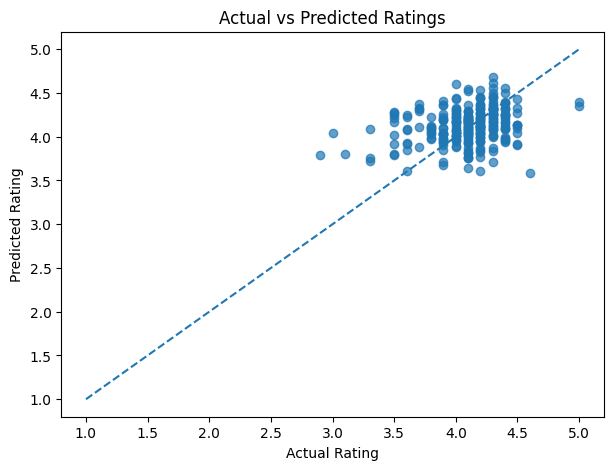

In [13]:
comparison = pd.DataFrame({
    "Actual Rating": y_test,
    "Predicted Rating": np.round(predictions, 2),
    "Absolute Error": np.round(np.abs(y_test - predictions), 2)
})

display(comparison.head(15))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.7)
plt.plot([1, 5], [1, 5], "--")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Ratings")
plt.show()

In [15]:
def predict_rating(review, category="Electronics"):
    review = re.sub(r"\s+", " ", str(review).lower()).strip()

    numeric = np.array(
        [[999, 1499, 33, 100]], dtype=np.float32
    )
    numeric = scaler.transform(numeric).astype(np.float32)

    inputs = {
        "review_text": tf.constant([review], dtype=tf.string),
        "numeric_features": numeric,
        "category": tf.constant([category], dtype=tf.string)
    }

    result = model.predict(inputs, verbose=0)[0][0]

    return round(float(np.clip(result, 1, 5)), 2)


print("Positive review rating:",
      predict_rating("Excellent product, great quality and works perfectly."))

print("Negative review rating:",
      predict_rating("Poor quality, battery drains quickly and stopped working."))

Positive review rating: 2.64
Negative review rating: 2.6


In [16]:
predictions = model.predict(test_inputs, verbose=0).flatten()
predictions = np.clip(predictions, 1, 5)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

MAE: 0.2261
RMSE: 0.2998
R2 Score: -0.1151


   Actual Rating  Predicted Rating
0            4.3          4.325010
1            4.1          4.077554
2            4.3          4.017733
3            3.9          3.903484
4            3.9          4.197713
5            3.5          3.797412
6            4.2          4.072207
7            4.4          4.250800
8            4.2          4.266385
9            4.0          4.223527


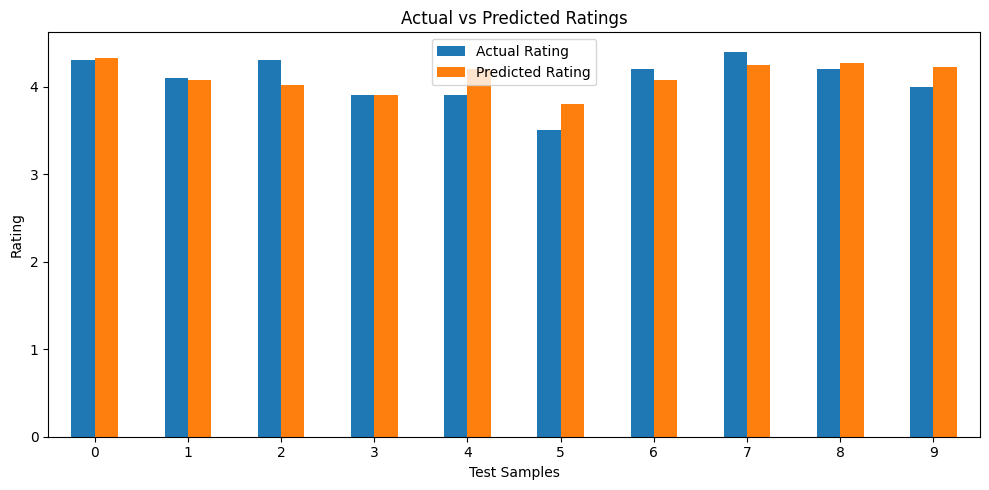

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Actual Rating": y_test.values if hasattr(y_test, "values") else y_test,
    "Predicted Rating": predictions
})

print(comparison.head(10))

comparison.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Actual vs Predicted Ratings")
plt.xlabel("Test Samples")
plt.ylabel("Rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
# Test with new, unseen customer reviews

review1 = "Excellent product, great quality and works perfectly."
review2 = "Poor quality, battery drains quickly and stopped working."

rating1 = predict_rating(review1)
rating2 = predict_rating(review2)

print("Review 1:", review1)
print("Predicted Rating:", rating1)

print("\nReview 2:", review2)
print("Predicted Rating:", rating2)

Review 1: Excellent product, great quality and works perfectly.
Predicted Rating: 2.64

Review 2: Poor quality, battery drains quickly and stopped working.
Predicted Rating: 2.6
